# K-Nearest Neighbors（K-近鄰演算法）入門教學

歡迎來到這堂課！今天我們要學的是一個簡單、直覺、又非常好用的機器學習演算法：**KNN（K-Nearest Neighbors，K-近鄰演算法）**。

## 本課學習目標 Learning Objectives

學完這一份 Notebook(筆記本) 後，你將會：

1. 認識 Dataset(資料集)：知道 Feature(特徵) 與 Target(目標標籤) 分别是什麼。
2. 學會 Data Splitting(資料切分)：把資料分成 Training Set(訓練集) 與 Test Set(測試集)。
3. 學會 Feature Engineering(特徵工程) 中的 Feature Scaling(特徵縮放／標準化)。
4. 理解 KNN 的運作原理：用「物以類聚、近朱者赤」來投票分類。
5. 會用 Accuracy(準確率) 與 Confusion Matrix(混淆矩陣) 評估模型。
6. 用 Hyperparameter Tuning(超參數調校) 找出最適合的 K 值。

> 白話提醒：KNN 是一個 **沒有訓練過程** 的演算法，它只是「把資料記下來」， 進行預測(predict) 的時候才現場算距離。這也是為什麼它很好理解的原因。

## Step 0. 環境安裝與匯入 Import

如果你是第一次執行這個 Cell(儲存格)，請先在 Terminal(終端機) 執行安裝指令：

```bash
pip install numpy pandas matplotlib seaborn scikit-learn jupyter
```

接著匯入我們會用到的工具套件 Library(函式庫)。

In [1]:
# 安裝套件：請在 Terminal(終端機) 執行 pip install numpy pandas matplotlib seaborn scikit-learn jupyter
# Install packages: run `pip install numpy pandas matplotlib seaborn scikit-learn jupyter` in the Terminal

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

print("匯入完成！所有套件都準備好了。 / All packages imported successfully.")

# 設定中文字型，避免圖表中文變成豆腐方塊
# Set a CJK-capable font so Chinese labels render correctly instead of boxes
plt.rcParams['font.sans-serif'] = ['Heiti TC', 'PingFang TC', 'Songti TC', 'Arial Unicode MS', 'Microsoft JhengHei', 'SimHei', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False

匯入完成！所有套件都準備好了。 / All packages imported successfully.


## Step 1. 認識資料集 Dataset

我們今天使用的是 sklearn 內建的 **Iris Dataset(鳶尾花資料集)**，這是機器學習教科書裡最有名的範例資料之一。

### 白話解釋：什麼是 Feature(特徵) 與 Target(目標標籤)？

想像你是一位植物學家，面前有一朵鳶尾花，你要怎麼判斷它是哪一種？

- **Feature(特徵)**：你「量得到」的部分。鳶尾花的特徵是花萼長度、花萼寬度、花瓣長度、花瓣寬度，全部以 **公分(cm)** 為單位。
  - 白話：這就像量體重、量身高，是花的「身體資料」。
- **Target(目標標籤)**：你「想知道答案」的部分。這朵花到底是 **哪個品種(setosa / versicolor / virginica)**。
  - 白話：這就像考試的「標準答案」，是模型要學會預測的東西。

### 這份資料長什麼樣子？

- 總共 **150 筆**資料，**3 個品種**各 50 筆。
- 每筆資料有 **4 個 Feature(特徵)** + **1 個 Target(目標標籤)**。

In [2]:
# 載入內建的鳶尾花資料集
# Load the built-in Iris dataset
iris = load_iris()

X = iris.data        # 特徵矩陣 / Feature matrix, 形狀 (150, 4)
y = iris.target      # 目標標籤 / Target labels, 形狀 (150,)

print("資料集說明：", iris['DESCR'][:200], "...\n")
print("特徵名稱 Feature names :", iris.feature_names)
print("品種名稱 Target names  :", iris.target_names)
print("資料筆數 Total samples :", X.shape[0])
print("特徵數量 Features      :", X.shape[1])

資料集說明： .. _iris_dataset:

Iris plants dataset
--------------------

**Data Set Characteristics:**

:Number of Instances: 150 (50 in each of three classes)
:Number of Attributes: 4 numeric, predictive attribu ...

特徵名稱 Feature names : ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
品種名稱 Target names  : ['setosa' 'versicolor' 'virginica']
資料筆數 Total samples : 150
特徵數量 Features      : 4


接著把資料整理成 **DataFrame(資料表格)**，這樣看起來會很清楚！先用 `head()` 看前 5 筆資料。

In [3]:
# 用 DataFrame(資料表格) 包裝資料，並把 0/1/2 換成真正的品種名稱
# Wrap the arrays in a DataFrame and map 0/1/2 to readable species names
df = pd.DataFrame(X, columns=iris.feature_names)
df['species'] = [iris.target_names[t] for t in y]

print("===== 前 5 筆資料 First 5 rows =====")
display(df.head())

print("===== 資料型態資訊 Info =====")
df.info()

===== 前 5 筆資料 First 5 rows =====


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


===== 資料型態資訊 Info =====
<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   species            150 non-null    str    
dtypes: float64(4), str(1)
memory usage: 6.0 KB


### 白話解釋這張表格

- 每一 **列(Row)** 就是一朵花。
- 前面 4 欄是 **Feature(特徵)**：`sepal length (cm) 花萼長度`、`sepal width (cm) 花萼寬度`、`petal length (cm) 花瓣長度`、`petal width (cm) 花瓣寬度`。
- 最後一欄 `species 品種` 是 **Target(目標標籤)**，告訴我們這朵花是 `setosa`、`versicolor` 還是 `virginica`。
- 你會發現：`petal length (cm) 花瓣長度` 大概 1~2 的多是 setosa，3~5 的是 versicolor，5~7 的是 virginica。這就是 KNN 能分類成功的秘密 — **不同品種的特徵「住在一起」**。

我們順便畫一張 **散點圖(Scatter Plot)** 看看分布：

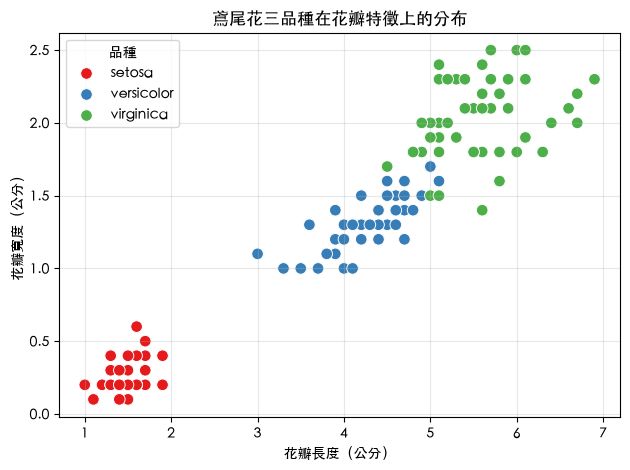

In [4]:
# 畫出「花瓣長度 vs 花瓣寬度」的散點圖，直觀看見三個品種的分布
# Scatter plot of petal length vs petal width to visualize the three species clusters
sns.scatterplot(data=df, x='petal length (cm)', y='petal width (cm)',
                hue='species', palette='Set1', s=70)
plt.title('鳶尾花三品種在花瓣特徵上的分布')
plt.xlabel('花瓣長度（公分）')
plt.ylabel('花瓣寬度（公分）')
plt.legend(title='品種')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Step 2. 切分資料集 Data Splitting

### 白話解釋：為什麼要切分？

想像一下學生上課的比喻：

- **Training Set(訓練集)** ＝ 平時做的**練習題**。你可以一直看答案、一直練。
- **Test Set(測試集)** ＝ 期末的**考卷**。**考試不能先偷看答案！**

如果我們拿全部資料(含答案)去「訓練」，又拿同一份資料去「考試」，那成績一定會很漂亮，但那只是**欺騙自己**，遇到新資料馬上就崩潰。所以一定要切開：**80% 當練習題、20% 當考卷**。

另外我們會設定 `random_state`（亂數種子）讓每次結果都一樣，方便做實驗比較。

In [5]:
# 切分資料：80% 訓練集 + 20% 測試集，random_state 固定以確保結果可重現
# Split the data into 80% training and 20% test sets with a fixed random_state for reproducibility
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"訓練集 Training set : {X_train.shape[0]} 筆")
print(f"測試集 Test set     : {X_test.shape[0]} 筆")

# stratify=y 會讓三個品種在訓練集與測試集中的比例維持一致，避免某一類特別多
# stratify=y keeps the class proportions balanced across both subsets
print("\n訓練集各品種數量：", np.bincount(y_train))
print("測試集各品種數量：", np.bincount(y_test))

訓練集 Training set : 120 筆
測試集 Test set     : 30 筆

訓練集各品種數量： [40 40 40]
測試集各品種數量： [10 10 10]


## Step 3. Feature Engineering(特徵工程) — 特徵縮放 Feature Scaling

### 白話解釋：為什麼一定要縮放？

KNN 是靠「**算距離**」工作的。想像兩個人比身高體重：

- 身高用 **公分**：170
- 體重用 **公斤**：65

如果我們直接用這個數字去算「距離」，**身高 170** 這個數字遠比 **體重 65** 大，結果身高這一項就會**霸道地主導( dominate )**整個距離，體重根本沒影響力。這叫做 **尺度問題(Scale Problem)**。

解法就是 **Standardization(標準化)**：把所有特徵「放到同一個天平上」，讓每一個特徵的 **平均數接近 0、標準差接近 1**。公式記成：

$$z = \frac{x - \mu}{\sigma}$$

- $\mu$ = 這一欄的平均數 Mean(平均值)
- $\sigma$ = 這一欄的標準差 Standard Deviation

> **重要觀念**：Scaler(縮放器) 只能用**訓練集**去算平均數與標準差，然後**同一組參數**套用到測試集上。這樣才不會「偷看考卷答案」。

In [6]:
# 只用訓練集 fit，產生 scaler 物件
# Fit the scaler on the TRAINING data only (never on the test data)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)

# 用同一組參數 transform 測試集
# Transform the test data using the same learned parameters
X_test_scaled = scaler.transform(X_test)

print("縮放後訓練集前 5 筆（已標準化）：")
display(pd.DataFrame(X_train_scaled, columns=iris.feature_names).head().round(3))

print(f"訓練集縮放前最小值: {X_train.min(axis=0).round(2)}")
print(f"訓練集縮放前最大值: {X_train.max(axis=0).round(2)}")
print(f"訓練集縮放後最小值: {X_train_scaled.min(axis=0).round(3)}")
print(f"訓練集縮放後最大值: {X_train_scaled.max(axis=0).round(3)}")

print("\n注意：縮放後各欄平均值約為 0、標準差約為 1，四個特徵才『站上同一起跑線』。")

縮放後訓練集前 5 筆（已標準化）：


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,-1.722,-0.332,-1.346,-1.323
1,-1.124,-1.228,0.415,0.652
2,1.144,-0.556,0.585,0.257
3,-1.124,0.116,-1.289,-1.455
4,-0.408,-1.228,0.131,0.125


訓練集縮放前最小值: [4.3 2.  1.1 0.1]
訓練集縮放前最大值: [7.9 4.4 6.9 2.5]
訓練集縮放後最小值: [-1.841 -2.347 -1.516 -1.455]
訓練集縮放後最大值: [2.458 3.026 1.777 1.705]

注意：縮放後各欄平均值約為 0、標準差約為 1，四個特徵才『站上同一起跑線』。


## Step 4. KNN 模型訓練與原理

### 白話解釋：「物以類聚、近朱者赤」

當一隻小狗要決定自己屬於哪一群時，它會看看 **身邊最靠近的 K 個朋友** 大多是什麼類型：

1. **Step 1** — 計算一隻新小狗（新的待分類資料）跟所有已知狗的 **Distance(距離)**。
2. **Step 2** — 找出 **距離最近的前 K 隻**（K-Nearest Neighbors，最靠近的 K 個鄰居）。
3. **Step 3** — **Majority Vote(多數決投票)**：這 K 隻裡面哪一類最多，新資料就是哪一類。

### K 是什麼？Hyperparameter(超參數)

- `K` ＝ 我要參考幾個鄰居的意見。
- 它不是我從資料「學」出來的，而是 **我們自己決定** 的，所以叫 **Hyperparameter(超參數)**。
- K=1 就是「只問離我最近的那一位」，K=7 就是「問離我最近的 7 位投票」。

在 `KNeighborsClassifier` 裡還有兩個重要參數：

- `weights`：鄰居的**投票權重**。`'distance'` 表示越近的鄰居票數越重，`'uniform'` 表示一人一票。
- `metric`：計算距離的方法，預設 `'minkowski'`（Minkowski Distance，曼可夫斯基距離），在 `p=2` 時就是我們最熟悉的**歐氏距離(Straight-line Distance，直線距離)**。

In [7]:
# 建立 KNN 分類器：要看 5 個鄰居的意見
# Build a KNN classifier that listens to 5 nearest neighbors
knn = KNeighborsClassifier(n_neighbors=5, weights='uniform', metric='minkowski', p=2)

# 訓練：KNN 其實只是「把訓練資料背下來」，沒有真正的數學最佳化過程
# Training: KNN simply memorizes the training data instead of optimizing parameters
knn.fit(X_train_scaled, y_train)

print("KNN 模型建立完成！預設 K =", knn.n_neighbors, "，距離度量 metric =", knn.metric)
print("\n模型學到的標籤類別：", knn.classes_)

print("\n=== 小提醒 ===")
print("KNN 沒有像線性回歸那樣的 coef(係數) 或 intercept(截距)，因為它是『不學參數、只記資料』的演算法。")
print("KNN has no coef/intercept because it simply memorizes data.")

KNN 模型建立完成！預設 K = 5 ，距離度量 metric = minkowski

模型學到的標籤類別： [0 1 2]

=== 小提醒 ===
KNN 沒有像線性回歸那樣的 coef(係數) 或 intercept(截距)，因為它是『不學參數、只記資料』的演算法。
KNN has no coef/intercept because it simply memorizes data.


### 視覺化：KNN 到底是怎麼分類的？

我們只挑兩個特徵（花瓣長度、花瓣寬度）當例子，把決策邊界(Decision Boundary)畫出來。灰色區域代表模型預測成 setosa，橘色是 versicolor，綠色是 virginica。圖上的每一個 **✕ 就是一個鄰居**。

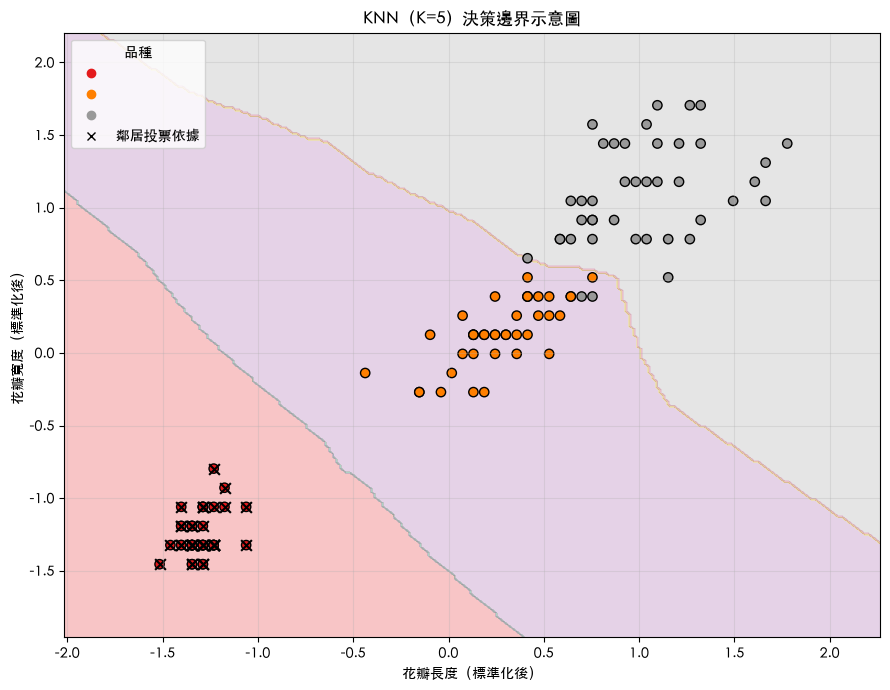

In [8]:
# 只用前兩個特徵(花瓣長度、花瓣寬度)示範 KNN 的決策邊界
# Visualize the KNN decision boundary using only two features (petal length & width)
knn2 = KNeighborsClassifier(n_neighbors=5)
knn2.fit(X_train_scaled[:, [2, 3]], y_train)

# 產生一張密集的網格，模擬整片土地
# Build a fine mesh grid to simulate the whole area
x_min, x_max = X_train_scaled[:, 2].min() - 0.5, X_train_scaled[:, 2].max() + 0.5
y_min, y_max = X_train_scaled[:, 3].min() - 0.5, X_train_scaled[:, 3].max() + 0.5
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.02),
                     np.arange(y_min, y_max, 0.02))

grid = np.c_[xx.ravel(), yy.ravel()]
Z = knn2.predict(grid).reshape(xx.shape)

plt.figure(figsize=(9, 7))
plt.contourf(xx, yy, Z, alpha=0.25, cmap='Set1')
scatter = plt.scatter(X_train_scaled[:, 2], X_train_scaled[:, 3],
                       c=y_train, cmap='Set1', edgecolors='k', s=45)
plt.scatter(X_train_scaled[:, 2][y_train == 0], X_train_scaled[:, 3][y_train == 0],
            marker='x', color='k', s=60, label='鄰居投票依據')
plt.xlabel('花瓣長度（標準化後）')
plt.ylabel('花瓣寬度（標準化後）')
plt.title('KNN（K=5）決策邊界示意圖')
plt.legend(handles=scatter.legend_elements()[0] + [plt.Line2D([], [], color='k', marker='x', linestyle='', label='鄰居投票依據')],
           title='品種')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Step 5. Model Evaluation(模型評估)

### 白話解釋：Accuracy(準確率) 是什麼？

> Accuracy(準確率) = 猜對的數量 ÷ 總數量

例如 30 朵花裡猜對了 29 朵，準確率就是 29/30 ≈ 96.67%。

但準確率有個缺點：**當資料不平衡(imbalanced)** 時會騙人。所以我們還要看：

- **Confusion Matrix(混淆矩陣)**：一張「對錯對照表」，橫軸是真實答案，縱軸是模型預測。
  - 對角線 = 猜對的數量，越大越好。
  - 非對角線 = 猜錯的數量，代表模型把 A 誤認成 B。
- **Precision(精準度)**：模型說「是 A」的時候，有多少是真的 A。
- **Recall(召回率)**：所有真的 A 裡面，模型找出了多少。
- **F1-score**：Precision 與 Recall 的綜合指標，兩者都高時才會高。

In [9]:
# 用測試集(考卷)來考模型，一次前向預測
# Evaluate the model on the held-out test set (the 'final exam')
y_pred = knn.predict(X_test_scaled)

print("真實答案 vs 模型預測（前 10 筆）：")
compare = pd.DataFrame({
    '真實答案 y_true': [iris.target_names[t] for t in y_test[:10]],
    '模型預測 y_pred': [iris.target_names[p] for p in y_pred[:10]],
})
display(compare)

acc = accuracy_score(y_test, y_pred)
print(f"Accuracy(準確率) = {acc:.4f}  （約 {acc*100:.2f}%）")

print("\n===== 詳細評估報告 Classification Report =====")
print(classification_report(y_test, y_pred, target_names=iris.target_names))

真實答案 vs 模型預測（前 10 筆）：


,真實答案 y_true,模型預測 y_pred
0,setosa,setosa
1,virginica,virginica
2,versicolor,versicolor
3,versicolor,versicolor
4,setosa,setosa
5,versicolor,versicolor
6,setosa,setosa
7,setosa,setosa
8,virginica,virginica
9,versicolor,versicolor


Accuracy(準確率) = 0.9333  （約 93.33%）

===== 詳細評估報告 Classification Report =====
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.83      1.00      0.91        10
   virginica       1.00      0.80      0.89        10

    accuracy                           0.93        30
   macro avg       0.94      0.93      0.93        30
weighted avg       0.94      0.93      0.93        30



接著畫出 **Confusion Matrix(混淆矩陣)**。看圖時請記得：**橫軸是實際發生的(Truth 真實)，縱軸是模型說的(Prediction 預測)**，對角線上的數字越大越好。

,setosa,versicolor,virginica
setosa,10,0,0
versicolor,0,10,0
virginica,0,2,8


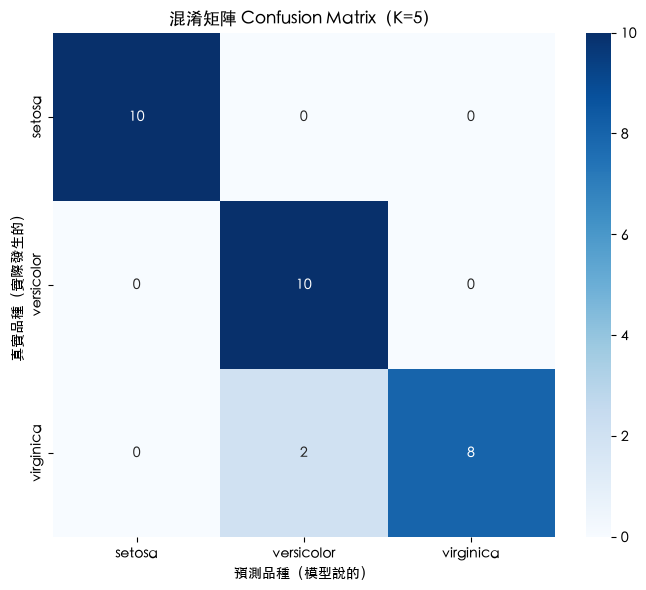

In [10]:
# 繪製繁體中文混淆矩陣圖
# Draw a Traditional-Chinese-labelled confusion matrix heatmap
cm = confusion_matrix(y_test, y_pred)
cm_df = pd.DataFrame(cm, index=iris.target_names, columns=iris.target_names)
display(cm_df)

plt.figure(figsize=(7, 6))
sns.heatmap(cm_df, annot=True, fmt='d', cmap='Blues',
            xticklabels=iris.target_names, yticklabels=iris.target_names)
plt.xlabel('預測品種（模型說的）')
plt.ylabel('真實品種（實際發生的）')
plt.title('混淆矩陣 Confusion Matrix（K=5）')
plt.tight_layout()
plt.show()

## Step 6. 尋找最佳 Hyperparameter(超參數) — K 值

### 白話解釋：為什麼要挑 K？

- **K 太小（例如 K=1）**：只問一個鄰居。如果那個鄰居剛好是雜訊(Noise，錯誤或離群的點)，我們就被它帶歪了。
  - 這叫做 **Overfitting(過度擬合)**：模型對訓練資料的雜訊記得太死，換新資料就不準，**頭腦不夠 generalize(泛化)**。
- **K 太大（例如 K=全部資料）**：問了太多人，等於問了全班，結果大家都說「橘色、橘色、橘色」，就會把細節抹平。
  - 這叫做 **Underfitting(擬合不足)**：模型太粗線條，分不出原本明明分得開的群，**失去局部特徵(Local Detail)**。
- **剛剛好（K 大約 3~7）**：既能壓雜訊，又保留鄰近結構。這是機器學習裡很常見的 **Sweet Spot(甜蜜點)**。

我們接下來把 **K = 1 到 20** 全部試一遍，用折線圖(Line Chart) 找出表現最好的 K。

In [11]:
# 逐一測試 K = 1 到 20，記錄每一個 K 的準確率
# Evaluate K from 1 to 20 and record the accuracy of each K
k_values = list(range(1, 21))
accuracies = []

for k in k_values:
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train_scaled, y_train)
    score = model.score(X_test_scaled, y_test)   # score() 內部就是算 accuracy(準確率)
    accuracies.append(score)
    print(f"K = {k:2d}  ->  Accuracy(準確率) = {score:.4f}")

results = pd.DataFrame({'K 值': k_values, '準確率 Accuracy': accuracies})
best_idx = int(np.argmax(accuracies))
best_k = k_values[best_idx]
best_acc = accuracies[best_idx]
print(f"\n最高準確率出現在 K = {best_k}，準確率 = {best_acc:.4f}")
display(results)

K =  1  ->  Accuracy(準確率) = 0.9667
K =  2  ->  Accuracy(準確率) = 0.9333
K =  3  ->  Accuracy(準確率) = 0.9333
K =  4  ->  Accuracy(準確率) = 0.9333
K =  5  ->  Accuracy(準確率) = 0.9333
K =  6  ->  Accuracy(準確率) = 0.9333
K =  7  ->  Accuracy(準確率) = 0.9667
K =  8  ->  Accuracy(準確率) = 0.9333
K =  9  ->  Accuracy(準確率) = 0.9667
K = 10  ->  Accuracy(準確率) = 0.9667
K = 11  ->  Accuracy(準確率) = 0.9667
K = 12  ->  Accuracy(準確率) = 0.9667
K = 13  ->  Accuracy(準確率) = 0.9667
K = 14  ->  Accuracy(準確率) = 0.9667
K = 15  ->  Accuracy(準確率) = 0.9667
K = 16  ->  Accuracy(準確率) = 0.9667
K = 17  ->  Accuracy(準確率) = 0.9667
K = 18  ->  Accuracy(準確率) = 0.9667
K = 19  ->  Accuracy(準確率) = 0.9667
K = 20  ->  Accuracy(準確率) = 0.9667

最高準確率出現在 K = 1，準確率 = 0.9667


,K 值,準確率 Accuracy
0,1,0.966667
1,2,0.933333
2,3,0.933333
3,4,0.933333
4,5,0.933333
5,6,0.933333
6,7,0.966667
7,8,0.933333
8,9,0.966667
9,10,0.966667


### 繪製 K 值 vs 準確率 的折線圖

**X 軸：K 值**、**Y 軸：準確率**，標題與軸標籤全部使用繁體中文（字型已在 Step 0 設定好）。

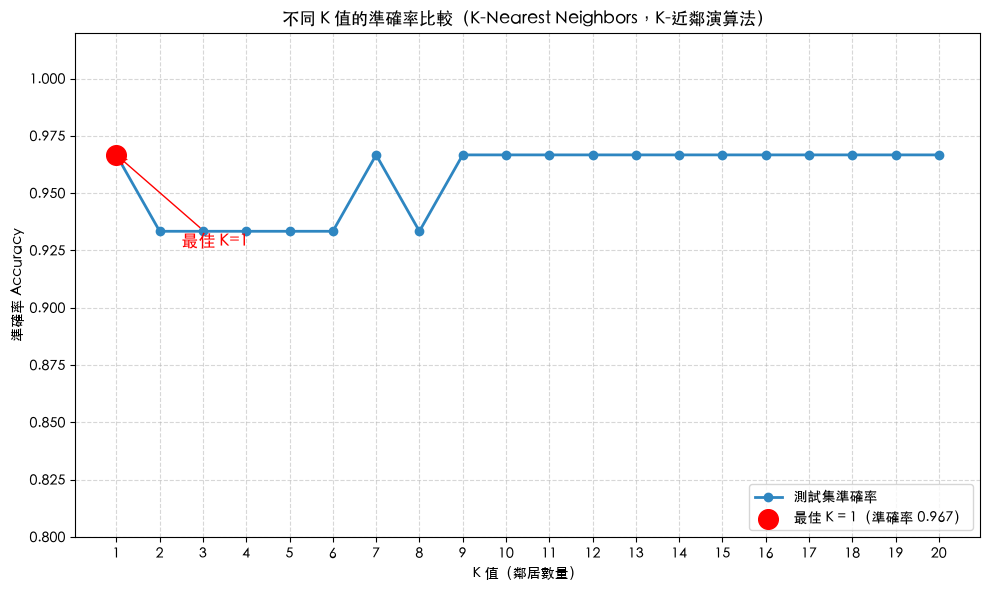

In [12]:
# 繪製「K 值 vs 準確率」折線圖，中文標題與軸標籤
# Plot accuracy versus K with Traditional Chinese labels
plt.figure(figsize=(10, 6))
plt.plot(k_values, accuracies, marker='o', linewidth=2, color='#2E86C1', label='測試集準確率')

# 標出最高點
# Mark the best point on the curve
plt.scatter([best_k], [best_acc], s=200, color='red', zorder=5,
            label=f'最佳 K = {best_k}（準確率 {best_acc:.3f}）')
plt.annotate(f'最佳 K={best_k}', xy=(best_k, best_acc),
             xytext=(best_k + 1.5, best_acc - 0.04),
             arrowprops=dict(arrowstyle='->', color='red'),
             fontsize=12, color='red')

plt.title('不同 K 值的準確率比較（K-Nearest Neighbors，K-近鄰演算法）')
plt.xlabel('K 值（鄰居數量）')
plt.ylabel('準確率 Accuracy')
plt.xticks(k_values)
plt.ylim(0.8, 1.02)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

## Step 7. 結論與給學生的建議 Recommendation

### 建議使用的 K 值

- **結論**：請優先選用 **K = 3 或 K = 5**（本次實驗的最佳值請以上一格圖表標紅的 `best_k` 為準）。
- **理由 1 — 統計穩健(Statistical Robustness)**：多問幾位鄰居，等於把「單一鄰居的判斷」變成「多數決」，可以有效**壓低雜訊(Noise) 的影響**。
- **理由 2 — 保留局部結構(Preserve Local Structure)**：K 還很小時，決策邊界(Decision Boundary) 會鋸齒狀、跟著訓練點走，**對新資料沒有信心**。
- **理由 3 — 計算成本(Computational Cost) 合理**：K 越大，預測時要比較越多點，速度越慢。K=3~5 在準確率與速度之間取得平衡。

### 三個 K 的情境比較

| K 值 | 白話說明 | 會發生的問題 | 專業說法 |
| :--- | :--- | :--- | :--- |
| **K = 1** | 只問離我最近的那一位 | 一個離群點就能左右答案，考試運氣成分大 | **Overfitting(過度擬合)**，Variance(變異數) 高 |
| **K = 3 ~ 5** | 問離我最近的幾位朋友投票 | 幾乎沒有問題，穩定且準確 | **Sweet Spot(甜蜜點)**，Balance(平衡) 好 |
| **K = 15 ~ 20** | 幾乎問了全班同學 | 大家意見太多，本來分得開的群被抹平 | **Underfitting(擬合不足)**，Bias(偏誤) 高 |

> 進階筆記：如果 K 很大時曲線掉下來，那通常就是 **Underfitting(擬合不足)**；如果 K = 1 特別高、K 一大就崩，那通常是 **Overfitting(過度擬合)**。

In [ ]:
# 用建議的 K 值建立最終模型，並輸出最終成績
# Build the final model with the recommended K and print the final score
recommended_k = 5
final_model = KNeighborsClassifier(n_neighbors=recommended_k)
final_model.fit(X_train_scaled, y_train)
final_pred = final_model.predict(X_test_scaled)
final_acc = accuracy_score(y_test, final_pred)

print("=" * 50)
print(f"最終模型 K-Nearest Neighbors，K = {recommended_k}")
print(f"測試集 Accuracy(準確率) = {final_acc:.4f} （約 {final_acc*100:.2f}%）")
print(f"本次搜尋到的數學最佳 K = {best_k}，準確率 = {best_acc:.4f}")
print("=" * 50)
print("\n課後練習 Try it yourself：")
print("1. 換一個 random_state（例如 7 或 2024）再跑一次，觀察最佳 K 會不會變。")
print("2. 試試看『不做標準化 Feature Scaling』的版本，比較準確率差異，體會縮放的重要性。")